# Forest Cover Type Classification - Exploratory Data Analysis

This notebook is the first stage of a machine learning project investigating model generalization and robustness on the Forest Cover Type dataset.

The objective is to understand the dataset's structure, identify potentially informative features, and investigate statistical relationships that may influence subsequent modeling decisions.

The next stages will focus on preprocessing, baseline model comparison, overfitting, and out-of-sample evaluation.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("../data/train.csv")

Let us conduct a first basic analysis of our dataset. The goal here is to grasp the overall structure of the dataset we are dealing with.

In [3]:
df.head()

,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,242642,2881,130,22,210,54,1020,250,221,88,...,0,0,0,0,0,0,0,0,0,1
1,309891,3005,351,14,242,-16,1371,194,215,159,...,0,0,0,0,0,0,0,0,0,1
2,287847,3226,63,14,618,2,1092,232,210,107,...,0,0,0,0,0,0,0,0,0,1
3,516307,3298,317,8,661,60,752,198,233,174,...,0,0,0,0,0,0,0,0,0,1
4,124860,3080,35,6,175,26,3705,219,227,144,...,0,0,0,0,0,0,0,0,0,1


In [4]:
print(f"The dataset is composed of {df.shape[0]} samples and {df.shape[1]-2} features.")

The dataset is composed of 15120 samples and 54 features.


In [5]:
print(df.dtypes.value_counts())
print(df.nunique())

int64    56
Name: count, dtype: int64
Id                                    15120
Elevation                              1676
Aspect                                  361
Slope                                    51
Horizontal_Distance_To_Hydrology        397
Vertical_Distance_To_Hydrology          433
Horizontal_Distance_To_Roadways        3274
Hillshade_9am                           176
Hillshade_Noon                          140
Hillshade_3pm                           248
Horizontal_Distance_To_Fire_Points     2764
Wilderness_Area1                          2
Wilderness_Area2                          2
Wilderness_Area3                          2
Wilderness_Area4                          2
Soil_Type1                                2
Soil_Type2                                2
Soil_Type3                                2
Soil_Type4                                2
Soil_Type5                                2
Soil_Type6                                2
Soil_Type7                            

We can easily guess, according to the number of unique values present in the columns, which features are continous, and which are categorical. 

In [6]:
n_categorical = int((df.nunique() < 10).sum())
n_continuous = df.shape[1]-n_categorical
print (f"The number of categorical variables is {n_categorical}.")
print (f"The number of continous variables is {n_continuous}.")

The number of categorical variables is 45.
The number of continous variables is 11.


Among our 55 features, we have 44 features that are categorical, and more precisely, binary, as it has been binarly encoded. Our response variable, Cover_Type, is also categorical, and can take 7 different values. We thus face a classification problem here.

From now on, let us split our data into a training set and test set that we will keep separated.

In [7]:
df_train, df_test = train_test_split(
    df, 
    test_size=0.2, 
    stratify=df["Cover_Type"], 
    random_state=42)

Are the modalities of the response variable well-balanced, or are there any modalities that represent the vast majority ?

<Axes: xlabel='Cover_Type', ylabel='count'>

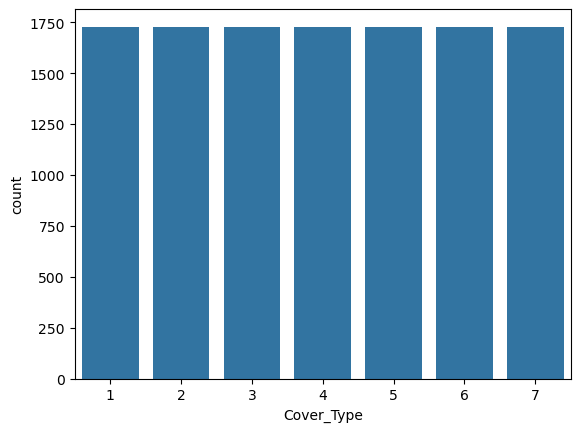

In [8]:
import seaborn as sns
sns.countplot(data=df_train, x="Cover_Type")

The modalities are perfectly balanced, which will spare us future problems in our classification models, such as the issue of the model not learning the data and still having a high accuracy score.

Let us now dive a little deeper into our dataset and check whether correlation trends between features can be identified.

<Axes: >

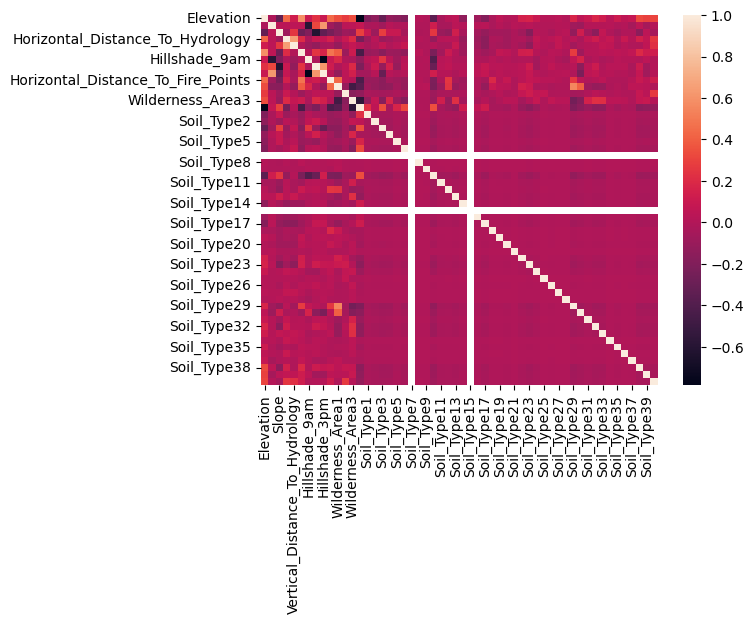

In [9]:
X = df_train.drop(columns=["Id", "Cover_Type"])
corr = X.corr()
sns.heatmap(corr)


The correlation matrix exhibits weak correlation between features, with a few notable exceptions. This suggests limited pairwise redundancy.
However, weak pairwise correlations do not allow us to exclude a possibility of multi-collinearity. One feature could be the sum of the other independent features.
Let us check what these few exceptions of weak pairwise correlation are.

In [10]:
min_corr = corr.mask(np.eye(len(corr), dtype=bool)).min().min()
max_corr = corr.mask(np.eye(len(corr), dtype=bool)).max().max()

arr_min = np.where(corr == min_corr) #The matrix is symmetric, so there are two arrays meeting the conditions. We only need one to determine the couple of features with the lower correlation.
arr_max = np.where(corr == max_corr)

print(f"The variables who are mostly inversely correlated are {tuple(corr.index[arr_min[0]])} with a correlation of {min_corr}")
print(f"The variables who are mostly inversely correlated are {tuple(corr.index[arr_max[0]])} with a correlation of {max_corr}")

The variables who are mostly inversely correlated are ('Elevation', 'Wilderness_Area4') with a correlation of -0.7821180957338508
The variables who are mostly inversely correlated are ('Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology') with a correlation of 0.6502257373826483


<Axes: xlabel='Elevation', ylabel='Slope'>

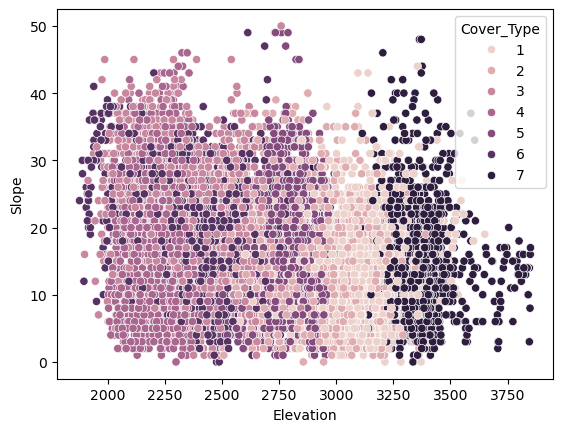

In [11]:
sns.scatterplot(data=df_train, x="Elevation", y="Slope", hue="Cover_Type")

<Axes: xlabel='Cover_Type', ylabel='Elevation'>

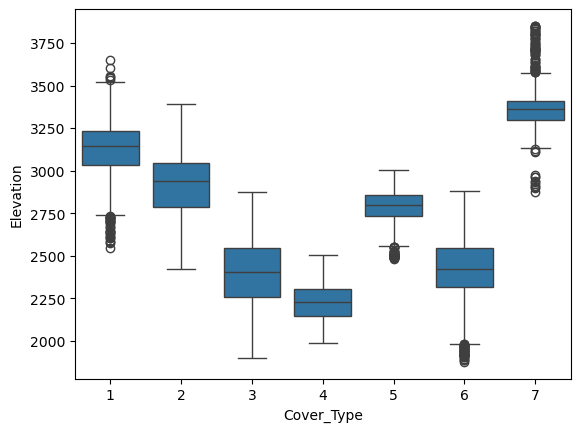

In [12]:
sns.boxplot(data=df_train, x="Cover_Type", y="Elevation")